MDA Experiment 2 -Image preprocessing

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving bird2.png to bird2.png


In [ ]:
image = cv2.imread(next(iter(uploaded)))

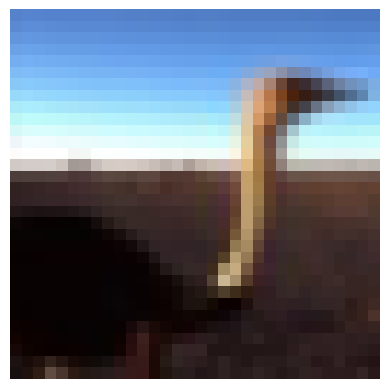

In [ ]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.axis("off")
plt.show()

In [ ]:
print("Original Image Size:", image.shape)

Original Image Size: (32, 32, 3)


In [ ]:
resized_image = cv2.resize(image, (224, 224))

In [ ]:
print("Resized Image Size:", resized_image.shape)

Resized Image Size: (224, 224, 3)


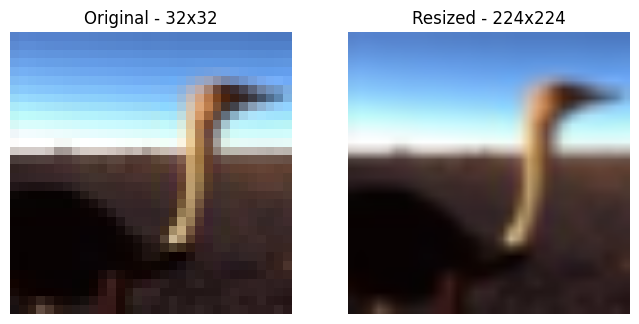

In [ ]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original - 32x32")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
plt.title("Resized - 224x224")
plt.axis("off")

plt.show()

In [ ]:
original_224 = cv2.resize(image, (224, 224))

difference = cv2.absdiff(original_224, resized_image)

print("Difference Shape:", difference.shape)
print("Mean Difference:", np.mean(difference))
print("Maximum Difference:", np.max(difference))

Difference Shape: (224, 224, 3)
Mean Difference: 0.0
Maximum Difference: 0


Normalization


In [ ]:
normalized_image = resized_image / 255.0

In [ ]:
print("Normalized Image Shape:", normalized_image.shape)
print("Minimum Pixel Value:", normalized_image.min())
print("Maximum Pixel Value:", normalized_image.max())

Normalized Image Shape: (224, 224, 3)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


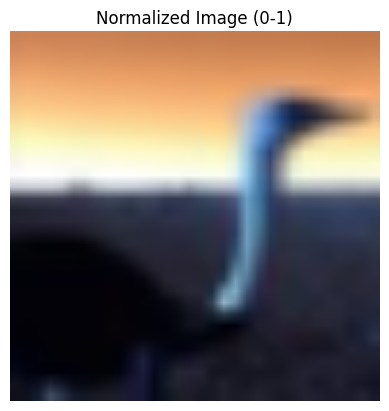

In [ ]:
plt.imshow(normalized_image)
plt.title("Normalized Image (0-1)")
plt.axis("off")
plt.show()

In [ ]:
print("Original Pixel Value:")
print(resized_image[0, 0])

print("\nNormalized Pixel Value:")
print(normalized_image[0, 0])

Original Pixel Value:
[203 130  86]

Normalized Pixel Value:
[0.79607843 0.50980392 0.3372549 ]


Data Augmentation


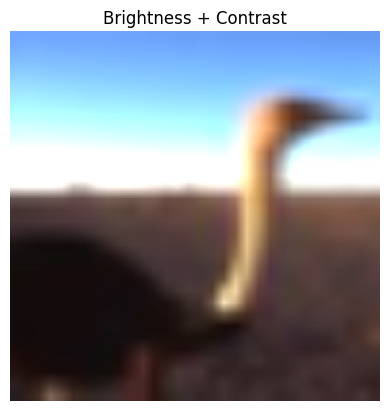

In [ ]:
# Brightness and contrast adjustment
alpha = 1.2   # Contrast
beta = 10     # Brightness

augmented_image = cv2.convertScaleAbs(
    resized_image,
    alpha=alpha,
    beta=beta
)

plt.imshow(cv2.cvtColor(augmented_image, cv2.COLOR_BGR2RGB))
plt.title("Brightness + Contrast")
plt.axis("off")
plt.show()

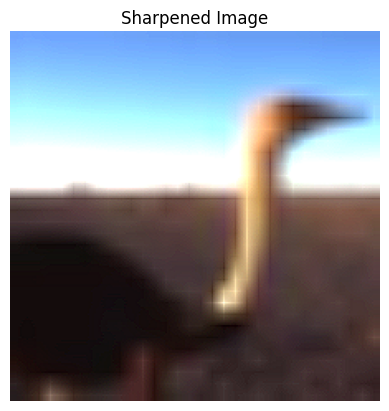

In [ ]:
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened_image = cv2.filter2D(augmented_image, -1, kernel)

plt.imshow(cv2.cvtColor(sharpened_image, cv2.COLOR_BGR2RGB))
plt.title("Sharpened Image")
plt.axis("off")
plt.show()

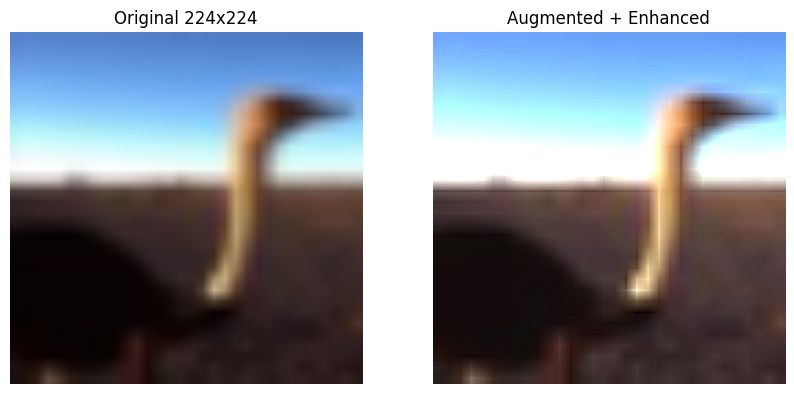

In [ ]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
plt.title("Original 224x224")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sharpened_image, cv2.COLOR_BGR2RGB))
plt.title("Augmented + Enhanced")
plt.axis("off")

plt.show()

In [ ]:
print("Original Size:", resized_image.shape)
print("Augmented Size:", sharpened_image.shape)
print("Contrast (alpha):", alpha)
print("Brightness (beta):", beta)

Original Size: (224, 224, 3)
Augmented Size: (224, 224, 3)
Contrast (alpha): 1.2
Brightness (beta): 10


Features Extraction using VGG16

In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
import numpy as np

In [ ]:
vgg_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
image_augmented = np.expand_dims(sharpened_image, axis=0)

image_augmented = preprocess_input(image_augmented)

In [ ]:
features_false = vgg_model.predict(image_augmented)

print("Feature Shape:", features_false.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 772ms/step
Feature Shape: (1, 7, 7, 512)


Now include_top=True

In [ ]:
vgg_model_true = VGG16(
    weights="imagenet",
    include_top=True,
    input_shape=(224, 224, 3)
)

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [ ]:
predictions_true = vgg_model_true.predict(image_augmented)

print("Prediction Shape:", predictions_true.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 946ms/step
Prediction Shape: (1, 1000)


In [ ]:
from tensorflow.keras.applications.vgg16 import decode_predictions

result = decode_predictions(predictions_true, top=5)

for _, label, probability in result[0]:
    print(label, ":", probability)

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
hook : 0.16338398
car_mirror : 0.07460422
buckle : 0.03844109
lighter : 0.023584273
parking_meter : 0.020940298


Created by - Areeba Khanam